<div><center><img src="https://ml.ucv.ai/logo.png" width="150"/></center></div>

# 06 Segmentación de imágenes con arquitecturas encoder-decoder

**Notebook base para la Tarea 2 (CNN & U-Nets).**

Este notebook entrena una red *encoder-decoder* que segmenta fotos de mascotas (dataset Oxford-IIIT Pet) en tres clases por píxel: **animal**, **fondo** y **borde**. La red que se entrena aquí es el **baseline** de la tarea: el punto de partida que ustedes deben mejorar.

Basado en [Image segmentation with a U-Net-like architecture](https://keras.io/examples/vision/oxford_pets_image_segmentation/) (Keras). Usa únicamente **Keras 3** con backend TensorFlow, que es lo que trae Google Colab por defecto.

Ejecútenlo con GPU (Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4).

> **Sobre el nombre.** El ejemplo original de Keras se titula "U-Net-*like*". La red que van a ver **no es una U-Net**: no tiene conexiones *skip* entre el encoder y el decoder. La sección 2.6 explica exactamente qué le falta. Averiguar cuánto mejora al agregarlas es parte de la tarea.

**Contenido**

1. Teoría: arquitecturas encoder-decoder
2. Los componentes de la red baseline (convoluciones separables, residuales, downsampling, upsampling, y qué es una U-Net)
3. Datos
4. La red baseline
5. Protocolo de evaluación (semilla, split, métricas)
6. Entrenamiento y análisis del baseline
7. Plantilla para sus experimentos

In [1]:
import os, time, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import tensorflow as tf            # solo para el pipeline de datos (tf.data)
import keras
from keras import layers

print("Keras", keras.__version__, "| backend:", keras.backend.backend())
print("GPUs disponibles:", tf.config.list_physical_devices("GPU"))
assert int(keras.__version__.split(".")[0]) >= 3, "Este notebook requiere Keras 3"

Keras 3.13.2 | backend: tensorflow
GPUs disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Configuración del protocolo

Todo lo que **no** es la arquitectura queda fijo aquí, para que los resultados de distintas redes (y de distintos estudiantes) sean comparables. **No modifiquen estos valores para la tarea**; el foco son los parámetros de la CNN, no el batch ni las épocas.

In [2]:
SEED          = 1337
IMG_SIZE      = (160, 160)      # imágenes y máscaras se redimensionan a esto
NUM_CLASSES   = 3
CLASS_NAMES   = ["animal", "fondo", "borde"]
BATCH_SIZE    = 32
VAL_SAMPLES   = 1000            # imágenes de validación (fijas gracias a la semilla)
MAX_TRAIN     = 1000            # subconjunto de entrenamiento: cada época dura segundos, no minutos
EPOCHS        = 40
LEARNING_RATE = 1e-4

keras.utils.set_random_seed(SEED)

# Paleta fija para dibujar máscaras: 0 animal, 1 fondo, 2 borde
MASK_CMAP = ListedColormap(["#e15759", "#4e79a7", "#f1ce63"])
def show_mask(ax, m, title=None):
    ax.imshow(m, cmap=MASK_CMAP, vmin=0, vmax=NUM_CLASSES - 1, interpolation="nearest")
    ax.axis("off")
    if title: ax.set_title(title)
def mask_legend(fig):
    fig.legend(handles=[Patch(color=MASK_CMAP(i), label=n) for i, n in enumerate(CLASS_NAMES)],
               loc="lower center", ncol=NUM_CLASSES, frameon=False)

# 1. Arquitecturas encoder-decoder (teoría)

Un modelo **encoder-decoder** transforma una entrada $\mathbf{x} \in \mathbb{R}^n$ en una salida $\mathbf{y} \in \mathbb{R}^m$ pasando por una representación latente $\mathbf{z} \in \mathbb{R}^d$, normalmente con $d < n$.

## 1.1 Encoder

El **encoder** convierte la entrada $\mathbf{x}$ en una representación latente $\mathbf{z}$:

$$\mathbf{z} = f_{\text{enc}}(\mathbf{x}; \theta_e), \qquad f_{\text{enc}}: \mathbb{R}^n \rightarrow \mathbb{R}^d$$

- $f_{\text{enc}}$: red neuronal (CNN, RNN, MLP, ...)
- $\theta_e$: parámetros del encoder
- $\mathbf{z}$: vector latente comprimido (típicamente $d < n$)

Si el encoder tiene múltiples capas: $\mathbf{z} = f_L \circ f_{L-1} \circ \dots \circ f_1(\mathbf{x})$.

## 1.2 Decoder

El **decoder** reconstruye o genera la salida a partir de $\mathbf{z}$:

$$\hat{\mathbf{y}} = f_{\text{dec}}(\mathbf{z}; \theta_d), \qquad f_{\text{dec}}: \mathbb{R}^d \rightarrow \mathbb{R}^m$$

## 1.3 El modelo completo

$$\hat{\mathbf{y}} = f_{\text{dec}}(f_{\text{enc}}(\mathbf{x})), \qquad f_{\text{dec}} \circ f_{\text{enc}}: \mathbb{R}^n \rightarrow \mathbb{R}^m$$

## 1.4 Función de pérdida

El modelo se entrena minimizando la pérdida entre la salida generada $\hat{\mathbf{y}}$ y la salida real $\mathbf{y}$:

$$\mathcal{L}(\mathbf{y}, \hat{\mathbf{y}}) = \mathcal{L}\left(\mathbf{y}, f_{\text{dec}}(f_{\text{enc}}(\mathbf{x}))\right)$$

Ejemplos comunes:

- **Reconstrucción (autoencoder):** $\mathcal{L} = \|\mathbf{x} - f_{\text{dec}}(f_{\text{enc}}(\mathbf{x}))\|^2$
- **Segmentación (por píxel):** $\mathcal{L} = \text{CrossEntropy}(\mathbf{y}, \hat{\mathbf{y}})$
- **Secuencia a secuencia (traducción):** $\mathcal{L} = -\sum_{t=1}^T \log P(y_t \mid \mathbf{z}, y_{<t})$

## 1.5 Optimización

El entrenamiento ajusta $\theta = \{\theta_e, \theta_d\}$ para minimizar la pérdida esperada sobre el conjunto de entrenamiento $\mathcal{D}$:

$$\theta^* = \arg \min_{\theta} \ \mathbb{E}_{(\mathbf{x}, \mathbf{y}) \sim \mathcal{D}} \left[ \mathcal{L}(\mathbf{y}, f_{\text{dec}}(f_{\text{enc}}(\mathbf{x}))) \right]$$

## 1.6 Segmentación como clasificación por píxel

En segmentación semántica la salida no es un vector sino un **mapa** $\hat{\mathbf{y}} \in \mathbb{R}^{H \times W \times C}$: en cada píxel $(i,j)$ hay una distribución softmax sobre las $C$ clases. La pérdida es la entropía cruzada promediada sobre todos los píxeles:

$$\mathcal{L} = -\frac{1}{HW}\sum_{i,j} \log \hat{y}_{ij,\, y_{ij}}$$

En Keras esto es `sparse_categorical_crossentropy` ("sparse" porque las etiquetas son enteros $0..C-1$, no vectores one-hot). Para que el mapa de salida tenga el mismo $H \times W$ que la entrada, el decoder tiene que **deshacer exactamente** las reducciones de resolución del encoder. De ahí que las dimensiones tengan que cuadrar capa por capa, y que valga la pena entender cada componente antes de tocarlo.

# 2. Los componentes de la red baseline

Antes de leer la red completa (sección 4), veamos cada pieza por separado con tensores de juguete. Todas las celdas de esta sección corren en segundos y sin datos.

## 2.1 Convolución: cuánto mide la salida

Para una convolución 2D con kernel $k$, stride $s$ y padding $p$ por lado:

$$H_{\text{out}} = \left\lfloor \frac{H_{\text{in}} + 2p - k}{s} \right\rfloor + 1$$

En Keras, `padding="same"` elige $p$ automáticamente para que $H_{\text{out}} = \lceil H_{\text{in}}/s \rceil$: con $s=1$ el tamaño no cambia y con $s=2$ se divide a la mitad. `padding="valid"` es $p=0$.

Parámetros de un `Conv2D` con $C_{\text{in}}$ canales de entrada y $C_{\text{out}}$ filtros: $k^2 \cdot C_{\text{in}} \cdot C_{\text{out}} + C_{\text{out}}$ (el último término es el sesgo).

In [3]:
x = keras.random.normal((1, 160, 160, 3))
for kw in [dict(strides=1, padding="same"), dict(strides=2, padding="same"),
           dict(strides=1, padding="valid"), dict(strides=2, padding="valid")]:
    conv = layers.Conv2D(16, 3, **kw)
    print(f"Conv2D(16, k=3, {kw})  →  {tuple(conv(x).shape)}   params = {conv.count_params()}")

Conv2D(16, k=3, {'strides': 1, 'padding': 'same'})  →  (1, 160, 160, 16)   params = 448
Conv2D(16, k=3, {'strides': 2, 'padding': 'same'})  →  (1, 80, 80, 16)   params = 448
Conv2D(16, k=3, {'strides': 1, 'padding': 'valid'})  →  (1, 158, 158, 16)   params = 448
Conv2D(16, k=3, {'strides': 2, 'padding': 'valid'})  →  (1, 79, 79, 16)   params = 448


## 2.2 `SeparableConv2D`: la convolución separable en profundidad

El baseline usa `SeparableConv2D` en el encoder (es la capa central de la arquitectura Xception). Descompone una convolución $k \times k$ en dos pasos:

1. **Depthwise**: un filtro $k \times k$ *por canal*, sin mezclar canales → $k^2 \cdot C_{\text{in}}$ parámetros.
2. **Pointwise**: una convolución $1 \times 1$ que mezcla los canales → $C_{\text{in}} \cdot C_{\text{out}}$ parámetros.

Frente a los $k^2 \cdot C_{\text{in}} \cdot C_{\text{out}}$ de una `Conv2D` normal, para $k=3$ y muchos canales el ahorro es de casi un orden de magnitud. La pregunta que ustedes deben responder experimentalmente: ¿cuánta calidad se pierde a cambio?

In [4]:
entrada = keras.Input((40, 40, 128))
conv = layers.Conv2D(128, 3, padding="same")
sep  = layers.SeparableConv2D(128, 3, padding="same")
conv(entrada); sep(entrada)          # llamar la capa la construye y fija sus pesos
print("Conv2D(128, k=3)          :", f"{conv.count_params():>8,}", "  = 3·3·128·128 + 128")
print("SeparableConv2D(128, k=3) :", f"{sep.count_params():>8,}",  "  = 3·3·128 + 128·128 + 128")
print(f"razón: {conv.count_params() / sep.count_params():.1f}×")

Conv2D(128, k=3)          :  147,584   = 3·3·128·128 + 128
SeparableConv2D(128, k=3) :   17,664   = 3·3·128 + 128·128 + 128
razón: 8.4×


## 2.3 Conexiones residuales y la proyección $1 \times 1$

Cada bloque del baseline suma su salida con la salida del bloque anterior (`layers.add`). Esa suma solo está definida si los dos tensores tienen **exactamente** la misma forma $(H, W, C)$. Pero el bloque cambia las dos cosas: reduce $H, W$ (pooling) y aumenta $C$ (más filtros). Por eso el camino residual lleva una **proyección**: una `Conv2D` de kernel $1 \times 1$ que ajusta los canales, con `strides=2` para ajustar la resolución.

Si al modificar la red ven un error del tipo *"Inputs have incompatible shapes"*, casi siempre es esto: algo cambió en el camino principal y la proyección residual ya no cuadra.

In [5]:
anterior = keras.random.normal((1, 80, 80, 32))   # salida del bloque anterior
actual   = keras.random.normal((1, 40, 40, 64))   # salida del bloque actual (pooling + más filtros)

try:
    layers.add([anterior, actual])
except Exception as e:
    print("Error esperado →", type(e).__name__, ":", str(e).splitlines()[0][:110])

proyeccion = layers.Conv2D(64, 1, strides=2, padding="same")(anterior)   # 1×1, stride 2
print("proyección:", tuple(proyeccion.shape), "→ ahora la suma sí funciona:",
      tuple(layers.add([proyeccion, actual]).shape))

Error esperado → ValueError : Inputs have incompatible shapes. Received shapes (80, 80, 32) and (40, 40, 64)
proyección: (1, 40, 40, 64) → ahora la suma sí funciona: (1, 40, 40, 64)


## 2.4 Downsampling: cómo reducir la resolución

Dos formas de pasar de $H \times W$ a $H/2 \times W/2$:

- **`MaxPooling2D(pool_size, strides=2)`**: sin parámetros, toma el máximo local. El baseline usa `pool_size=3, strides=2` (ventanas solapadas), una elección heredada de Xception.
- **Convolución con `strides=2`**: aprende cómo reducir. Es lo que hace el bloque de entrada (`Conv2D(32, 3, strides=2)`) y la proyección residual (`Conv2D(f, 1, strides=2)`).

Cada reducción duplica el *campo receptivo* relativo de las capas siguientes. En el cuello de botella del baseline (10×10 para una entrada de 160×160) cada posición latente resume una región de 16×16 píxeles de la imagen. Esa compresión es lo que permite reconocer **qué** hay en la imagen, y también lo que hace perder **dónde** está exactamente cada cosa.

## 2.5 Upsampling: cómo recuperar la resolución (lean esto con cuidado)

El decoder tiene que volver de 10×10 a 160×160. Hay tres maneras habituales de duplicar $H \times W$:

1. **`UpSampling2D(2)`**: interpolación fija (vecino más cercano por defecto, o `interpolation="bilinear"`). **Cero parámetros.** Suele ir seguida de una convolución normal que "refina" el resultado.
2. **`Conv2DTranspose(f, k, strides=2, padding="same")`**: convolución transpuesta, un upsampling **aprendido**. Con `padding="same"`, $H_{\text{out}} = s \cdot H_{\text{in}}$. La fórmula general es $H_{\text{out}} = (H_{\text{in}}-1)\,s - 2p + k$. Cuando $k$ no es múltiplo de $s$ (por ejemplo $k=3$, $s=2$) tiende a producir artefactos de tablero de ajedrez (Odena et al., 2016).
3. **`UpSampling2D` + `Conv2D`**: la combinación de la opción 1. Barata, sin artefactos, y la que usan muchas U-Nets modernas.

**La trampa del baseline.** El código usa `Conv2DTranspose(f, 3, padding="same")` **sin especificar `strides`**, y el valor por defecto es `strides=1`. Con stride 1 y padding `same`, la convolución transpuesta **no cambia el tamaño**: 10×10 entra, 10×10 sale. En ese régimen es matemáticamente equivalente a una `Conv2D` normal (mismos parámetros, misma capacidad). Quien realmente duplica la resolución en el baseline es `UpSampling2D(2)`. Es decir: el decoder del baseline es *"conv, conv, interpolar ×2"*, **no** upsampling aprendido, aunque el nombre de la capa sugiera lo contrario. Compruébenlo:

In [6]:
z = keras.random.normal((1, 10, 10, 256))    # el cuello de botella del baseline
opciones = {
    'Conv2DTranspose(256, k=3, strides=1, "same")  ← lo que usa el baseline': layers.Conv2DTranspose(256, 3, padding="same"),
    'Conv2DTranspose(256, k=3, strides=2, "same")':                           layers.Conv2DTranspose(256, 3, strides=2, padding="same"),
    'Conv2D(256, k=3, "same")  (para comparar params)':                       layers.Conv2D(256, 3, padding="same"),
    'UpSampling2D(2)  nearest':                                               layers.UpSampling2D(2),
    'UpSampling2D(2, interpolation="bilinear")':                              layers.UpSampling2D(2, interpolation="bilinear"),
}
for nombre, capa in opciones.items():
    y = capa(z)
    print(f"{nombre:66s} → {str(tuple(y.shape)):18s} params = {capa.count_params():,}")

Conv2DTranspose(256, k=3, strides=1, "same")  ← lo que usa el baseline → (1, 10, 10, 256)   params = 590,080
Conv2DTranspose(256, k=3, strides=2, "same")                       → (1, 20, 20, 256)   params = 590,080
Conv2D(256, k=3, "same")  (para comparar params)                   → (1, 10, 10, 256)   params = 590,080
UpSampling2D(2)  nearest                                           → (1, 20, 20, 256)   params = 0
UpSampling2D(2, interpolation="bilinear")                          → (1, 20, 20, 256)   params = 0


## 2.6 ¿Qué es una U-Net, y por qué el baseline no lo es?

La **U-Net** (Ronneberger et al., 2015) es un encoder-decoder simétrico con una adición clave: **conexiones *skip* del encoder al decoder**. El mapa de características del encoder en la resolución $r$ se **concatena** (no se suma) con el mapa del decoder cuando este vuelve a la resolución $r$:

$$\mathbf{d}_\ell = g_\ell\big(\,[\,\text{Up}(\mathbf{d}_{\ell+1})\;\|\;\mathbf{e}_\ell\,]\,\big)$$

donde $\mathbf{e}_\ell$ es la salida del encoder en el nivel $\ell$, $\|$ es la concatenación por canales y $g_\ell$ son las convoluciones del bloque. Dibujada, la red tiene forma de **U**: bajando por la izquierda, subiendo por la derecha, y con puentes horizontales entre niveles de igual resolución.

**Por qué importa.** Al pasar por el cuello de botella (10×10) la red pierde la información espacial fina; el decoder tiene que *reinventar* dónde estaban exactamente los contornos a partir de un mapa 16 veces más pequeño. Las skips le dan al decoder acceso directo a los mapas de alta resolución del encoder. La clase **borde**, la más difícil de este dataset, es la que más se beneficia.

**El baseline tiene conexiones residuales, no skips.** Las residuales (`layers.add`) conectan cada bloque con el bloque *inmediatamente anterior*, dentro de la misma mitad de la red. **No hay ninguna conexión que cruce del encoder al decoder.** Así que la red es un encoder-decoder con residuales, no una U-Net.

| | Residual (`add`) | Skip de U-Net (`Concatenate`) |
|---|---|---|
| Conecta | bloque $\ell$ con bloque $\ell-1$, misma mitad | encoder nivel $\ell$ con decoder nivel $\ell$ |
| Operación | suma elemento a elemento | apila canales |
| Requisito de forma | mismos $H, W, C$ (por eso la proyección 1×1) | mismos $H, W$; los canales se suman |
| Para qué | facilitar el flujo del gradiente | recuperar detalle espacial en el decoder |

Convertir el baseline en una U-Net es una de las mejoras que pueden probar en la tarea. Pista: guarden las salidas del encoder en 80×80, 40×40 y 20×20 y úsenlas en el decoder cuando vuelva a cada una de esas resoluciones. Al concatenar cambia el número de canales, así que la proyección residual tiene que seguir cuadrando.

In [7]:
enc = keras.random.normal((1, 40, 40, 64))     # mapa del encoder en 40×40
dec = keras.random.normal((1, 40, 40, 128))    # mapa del decoder tras subir de 20×20 a 40×40
print("Concatenate([dec, enc]) →", tuple(layers.Concatenate()([dec, enc]).shape), "  (128 + 64 canales)")
print("add([dec, enc])         → requiere los mismos canales; habría que proyectar uno de los dos")

Concatenate([dec, enc]) → (1, 40, 40, 192)   (128 + 64 canales)
add([dec, enc])         → requiere los mismos canales; habría que proyectar uno de los dos


# 3. Datos: Oxford-IIIT Pet

7 390 fotos de perros y gatos (37 razas). Cada foto trae un **trimap**: una imagen del mismo tamaño con un entero por píxel, `1` = animal, `2` = fondo, `3` = borde / indefinido. Restaremos 1 para tener clases `0, 1, 2`.

## 3.1 Descarga (~800 MB, una sola vez por sesión de Colab)

In [8]:
if not os.path.isdir("images"):
    !wget -q https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
    !tar -xf images.tar.gz
if not os.path.isdir("annotations"):
    !wget -q https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz
    !tar -xf annotations.tar.gz
print(len(os.listdir("images")), "archivos en images/ |",
      len(os.listdir("annotations/trimaps")), "en annotations/trimaps/")

7393 archivos en images/ | 14780 en annotations/trimaps/


## 3.2 Emparejar cada imagen con su máscara

Los nombres coinciden salvo por la extensión (`Abyssinian_1.jpg` ↔ `Abyssinian_1.png`). Ordenamos ambas listas y verificamos el emparejamiento uno a uno; la carpeta de trimaps trae además archivos ocultos `._*.png` que hay que descartar.

In [9]:
input_img_paths = sorted(os.path.join("images", f) for f in os.listdir("images") if f.endswith(".jpg"))
target_img_paths = sorted(os.path.join("annotations/trimaps", f) for f in os.listdir("annotations/trimaps")
                          if f.endswith(".png") and not f.startswith("."))

assert len(input_img_paths) == len(target_img_paths), "distinta cantidad de imágenes y máscaras"
stem = lambda p: os.path.splitext(os.path.basename(p))[0]
for img_p, mask_p in zip(input_img_paths, target_img_paths):
    assert stem(img_p) == stem(mask_p), f"desemparejado: {img_p} vs {mask_p}"

print("Pares imagen/máscara:", len(input_img_paths))
for img_p, mask_p in list(zip(input_img_paths, target_img_paths))[:3]:
    print("  ", img_p, "|", mask_p)

Pares imagen/máscara: 7390
   images/Abyssinian_1.jpg | annotations/trimaps/Abyssinian_1.png
   images/Abyssinian_10.jpg | annotations/trimaps/Abyssinian_10.png
   images/Abyssinian_100.jpg | annotations/trimaps/Abyssinian_100.png


## 3.3 Un ejemplo

tamaño original: (500, 448) | valores presentes en el trimap: [1 2 3]


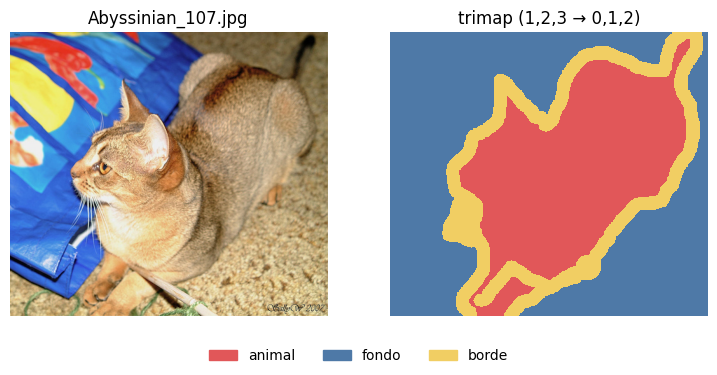

In [10]:
i = 9
img = keras.utils.load_img(input_img_paths[i])
trimap = np.array(keras.utils.load_img(target_img_paths[i], color_mode="grayscale"))
print("tamaño original:", img.size, "| valores presentes en el trimap:", np.unique(trimap))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(img); ax[0].axis("off"); ax[0].set_title(os.path.basename(input_img_paths[i]))
show_mask(ax[1], trimap - 1, "trimap (1,2,3 → 0,1,2)")
mask_legend(fig)
plt.show()

## 3.4 Pipeline de datos y split fijo

- Se leen los archivos con `tf.data` (paralelo y con caché en memoria: ~2 000 imágenes de 160×160 caben sin problema).
- No todas las imágenes del dataset están realmente codificadas como JPEG aunque tengan esa extensión; `tf.io.decode_image` detecta el formato a partir del contenido.
- Las imágenes se redimensionan con interpolación bilineal y se normalizan a $[0, 1]$. Las máscaras se redimensionan con **vecino más cercano**: interpolar etiquetas inventaría clases intermedias (¿qué es la clase 1.5?).
- El split se hace barajando los pares con la semilla fija: mismas 1 000 imágenes de validación para todos, y mismas 1 000 de entrenamiento.

In [11]:
AUTOTUNE = tf.data.AUTOTUNE

def load_pair(img_path, mask_path):
    img = tf.io.read_file(img_path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)   # detecta jpg/png
    img = tf.image.resize(img, IMG_SIZE)                                # bilineal → float32
    img = img / 255.0                                                   # → [0, 1]

    mask = tf.io.read_file(mask_path)
    mask = tf.io.decode_png(mask, channels=1)
    mask = tf.image.resize(mask, IMG_SIZE, method="nearest")           # nearest: no inventar clases
    mask = tf.cast(mask, tf.int32) - 1                                  # 1,2,3 → 0,1,2
    return img, mask

def make_dataset(pairs, training=False):
    imgs, masks = zip(*pairs)
    ds = tf.data.Dataset.from_tensor_slices((list(imgs), list(masks)))
    ds = ds.map(load_pair, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(pairs), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

pairs = list(zip(input_img_paths, target_img_paths))
random.Random(SEED).shuffle(pairs)
val_pairs   = pairs[:VAL_SAMPLES]
train_pairs = pairs[VAL_SAMPLES:VAL_SAMPLES + MAX_TRAIN]

train_ds = make_dataset(train_pairs, training=True)
val_ds   = make_dataset(val_pairs)
print(f"entrenamiento: {len(train_pairs)} imágenes | validación: {len(val_pairs)} imágenes | "
      f"{len(pairs) - VAL_SAMPLES - MAX_TRAIN} sin usar")

entrenamiento: 1000 imágenes | validación: 1000 imágenes | 5390 sin usar


### Sanity check del batch

Siempre miren un batch antes de entrenar: formas, tipos, rango de valores y **distribución de clases**. Fíjense en qué fracción de los píxeles es *borde*: eso explica por qué la pixel accuracy no sirve como métrica principal (sección 5).

imágenes: (32, 160, 160, 3) float32 | rango [0.00, 1.00]
máscaras: (32, 160, 160, 1) int32 | clases: [0 1 2]
  animal :  27.4% de los píxeles
  fondo  :  61.4% de los píxeles
  borde  :  11.2% de los píxeles


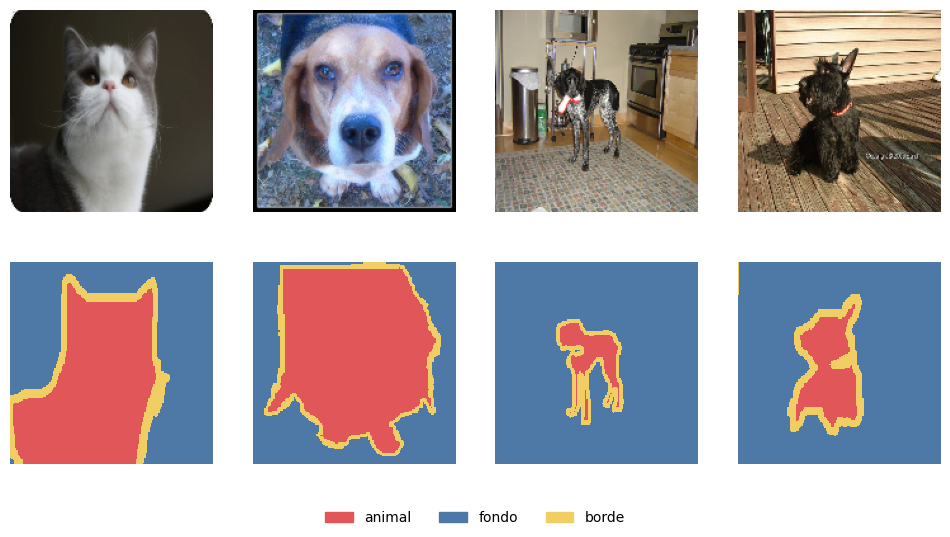

In [12]:
x_batch, y_batch = next(iter(val_ds))
print("imágenes:", tuple(x_batch.shape), x_batch.dtype.name,
      f"| rango [{float(tf.reduce_min(x_batch)):.2f}, {float(tf.reduce_max(x_batch)):.2f}]")
print("máscaras:", tuple(y_batch.shape), y_batch.dtype.name, "| clases:", np.unique(y_batch.numpy()))

frac = np.bincount(y_batch.numpy().ravel(), minlength=NUM_CLASSES) / y_batch.numpy().size
for c, f in zip(CLASS_NAMES, frac):
    print(f"  {c:7s}: {100 * f:5.1f}% de los píxeles")

fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for j in range(4):
    ax[0, j].imshow(x_batch[j]); ax[0, j].axis("off")
    show_mask(ax[1, j], y_batch[j, ..., 0])
mask_legend(fig)
plt.show()

# 4. La red baseline

Un encoder-decoder simétrico con residuales, estilo Xception. Léanla siguiendo los comentarios de forma; la tabla de abajo resume qué mide cada tensor para una entrada de 160×160.

Los argumentos `filters` y `kernel_size` están expuestos para que puedan variar el ancho, la profundidad y el tamaño de kernel sin reescribir la función. Para cambios estructurales (skips, otro tipo de upsampling, quitar residuales, cambiar `SeparableConv2D` por `Conv2D`, ...) copien la función, renómbrenla y modifíquenla.

In [13]:
def build_baseline(img_size, num_classes, filters=(64, 128, 256), kernel_size=3, name="baseline"):
    '''Encoder-decoder estilo Xception. SIN skip connections encoder→decoder.

    filters: filtros de cada bloque del encoder. El decoder los recorre al revés
                 y añade un bloque final de 32 filtros para volver a la resolución original.
    kernel_size: tamaño de kernel de las convoluciones de los bloques.
    '''
    inputs = keras.Input(shape=img_size + (3,))                             # (160, 160, 3)

    # Encoder
    # Bloque de entrada: convolución con stride 2 → mitad de resolución
    x = layers.Conv2D(32, 3, strides=2, padding="same")(inputs)             # (80, 80, 32)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    # se guarda para la conexión residual
    previous_block_activation = x

    for f in filters:                                                        # 64, 128, 256
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)             # H, W → H/2, W/2

        # Residual: igualar H, W (stride 2) y canales (f) antes de sumar
        residual = layers.Conv2D(f, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x
    # aquí x es el cuello de botella: (10, 10, 256) para una entrada de 160×160

    # Decoder
    # 256, 128, 64, 32
    for f in tuple(reversed(filters)) + (32,):
        x = layers.Activation("relu")(x)
        # strides=1: NO cambia H, W
        x = layers.Conv2DTranspose(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2DTranspose(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        # Aquí si cambiamos y aumentamos en un factor de 2
        # Esto es: H, W → 2H, 2W
        x = layers.UpSampling2D(2)(x)

        # Residual: igualar H, W (upsampling) y canales (conv 1×1)
        residual = layers.UpSampling2D(2)(previous_block_activation)
        residual = layers.Conv2D(f, 1, padding="same")(residual)
        x = layers.add([x, residual])
        previous_block_activation = x

    # Clasificador por píxel: un softmax de num_classes en cada posición  → (160, 160, 3)
    outputs = layers.Conv2D(num_classes, 3, activation="softmax", padding="same")(x)
    return keras.Model(inputs, outputs, name=name)

keras.utils.clear_session()      # nombres de capa limpios en el summary
model = build_baseline(IMG_SIZE, NUM_CLASSES)
model.summary(line_length=100)

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)    │ (None, 160, 160, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d (Conv2D)             │ (None, 80, 80, 32)      │            896 │ input_layer[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization         │ (None, 80, 80, 32)      │            128 │ conv2d[0][0]            │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ activation (Activation)     │ (None, 80, 80, 32)      │              0 │ batch_normalization[0]… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ activation_1 (Activation)   │ (None, 80, 80, 32)      │              0 │ activation[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ separable_conv2d            │ (None, 80, 80, 64)      │          2,400 │ activation_1[0][0]      │
│ (SeparableConv2D)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_1       │ (None, 80, 80, 64)      │            256 │ separable_conv2d[0][0]  │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ activation_2 (Activation)   │ (None, 80, 80, 64)      │              0 │ batch_normalization_1[… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ separable_conv2d_1          │ (None, 80, 80, 64)      │          4,736 │ activation_2[0][0]      │
│ (SeparableConv2D)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_2       │ (None, 80, 80, 64)      │            256 │ separable_conv2d_1[0][… │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ max_pooling2d               │ (None, 40, 40, 64)      │              0 │ batch_normalization_2[… │
│ (MaxPooling2D)              │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_1 (Conv2D)           │ (None, 40, 40, 64)      │          2,112 │ activation[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ add (Add)                   │ (None, 40, 40, 64)      │              0 │ max_pooling2d[0][0],    │
│                             │                         │                │ conv2d_1[0][0]          │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ activation_3 (Activation)   │ (None, 40, 40, 64)      │              0 │ add[0][0]               │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ separable_conv2d_2          │ (None, 40, 40, 128)     │          8,896 │ activation_3[0][0]      │
│ (SeparableConv2D)           │                         │    

 Total params: 2,058,979 (7.85 MB)

 Trainable params: 2,055,203 (7.84 MB)

 Non-trainable params: 3,776 (14.75 KB)

### Formas a lo largo de la red (entrada 160×160)

| Etapa | Salida $(H, W, C)$ |
|---|---|
| Entrada | 160 × 160 × 3 |
| `Conv2D(32, 3, strides=2)` | 80 × 80 × 32 |
| Bloque encoder 64 (2 `SeparableConv2D` + `MaxPool` s=2) | 40 × 40 × 64 |
| Bloque encoder 128 | 20 × 20 × 128 |
| Bloque encoder 256 → **cuello de botella** | 10 × 10 × 256 |
| Bloque decoder 256 (2 `Conv2DTranspose` s=1 → sigue 10×10; `UpSampling2D` ×2) | 20 × 20 × 256 |
| Bloque decoder 128 | 40 × 40 × 128 |
| Bloque decoder 64 | 80 × 80 × 64 |
| Bloque decoder 32 | 160 × 160 × 32 |
| `Conv2D(3, 3, softmax)` | 160 × 160 × 3 |

Ejercicio para el informe: reproduzcan esta tabla a mano a partir de las fórmulas de 2.1 y 2.5, y calculen cuántos parámetros tiene *un* bloque del encoder.

# 5. Protocolo de evaluación

## 5.1 Métricas

- **Pixel accuracy**: fracción de píxeles bien clasificados. Engañosa aquí: fondo y animal ocupan casi todos los píxeles, así que una red que ignore por completo el borde puede pasar del 90 %.
- **IoU (Intersection over Union) de la clase $c$**:

$$\text{IoU}_c = \frac{|P_c \cap T_c|}{|P_c \cup T_c|} = \frac{TP_c}{TP_c + FP_c + FN_c}$$

  con $P_c$ los píxeles predichos como $c$ y $T_c$ los que realmente son $c$. Penaliza tanto los falsos positivos como los falsos negativos, y una clase pequeña pesa igual que una grande.
- **Mean IoU (mIoU)**: promedio del IoU sobre las clases. **Es la métrica principal de la tarea.** Keras la implementa en `keras.metrics.MeanIoU`, acumulando una matriz de confusión a lo largo de toda la época. Como la red devuelve probabilidades softmax, hay que indicarle `sparse_y_pred=False` para que aplique el `argmax`.

> Las funciones `iou_metric` / `dice_coefficient` de la versión anterior de este notebook se eliminaron: estaban escritas para segmentación **binaria** (un canal y umbral 0.5) y con 3 clases producían un número sin significado.

## 5.2 Selección del modelo

`ModelCheckpoint(save_best_only=True, monitor="val_miou")` guarda los pesos de la mejor época de validación. El número que reportan es el **mejor val mIoU** y la época en que ocurrió. Fijamos las épocas y dejamos que el checkpoint escoja: así el "cuándo parar" no es una variable del experimento.

> **Reproducibilidad.** `keras.utils.set_random_seed` fija las semillas, pero algunas operaciones en GPU no son deterministas. Diferencias de ±0.01 en mIoU entre corridas idénticas son normales; una "mejora" de ese orden **no es una mejora**. Si tienen tiempo, entrenen su mejor arquitectura con 2–3 semillas y reporten media ± desviación.

## 5.3 La función que entrena cualquier arquitectura

In [14]:
RESULTS_FILE = "results.json"
results = {}
if os.path.exists(RESULTS_FILE):                    # permite retomar tras reiniciar el runtime
    with open(RESULTS_FILE) as f:
        results = json.load(f)
    print("Resultados previos cargados:", list(results))

def run_experiment(name, build_fn, epochs=EPOCHS):
    '''Entrena una arquitectura bajo el protocolo fijo y registra sus resultados en `results`.'''
    keras.utils.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_fn()
    model.compile(
        optimizer=keras.optimizers.Adam(LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy",
                 keras.metrics.MeanIoU(num_classes=NUM_CLASSES, sparse_y_pred=False, name="miou")],
    )
    os.makedirs("checkpoints", exist_ok=True)
    ckpt_path = f"checkpoints/{name}.keras"
    callbacks = [keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_miou", mode="max", save_best_only=True)]

    print(f"[{name}] {model.count_params():,} parámetros")
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks,
                     shuffle=False,   # el Dataset ya baraja; esto solo evita un warning
                     verbose=2)
    elapsed = time.time() - t0

    best = int(np.argmax(hist.history["val_miou"]))
    results[name] = {
        "params": int(model.count_params()),
        "epochs": epochs,
        "seconds_per_epoch": elapsed / epochs,
        "best_epoch": best,
        "best_val_miou": float(hist.history["val_miou"][best]),
        "best_val_acc": float(hist.history["val_accuracy"][best]),
        "checkpoint": ckpt_path,
        "history": {k: [float(v) for v in vals] for k, vals in hist.history.items()},
    }
    with open(RESULTS_FILE, "w") as f:
        json.dump(results, f, indent=1)
    print(f"[{name}] mejor val mIoU = {results[name]['best_val_miou']:.4f} en la época {best + 1} "
          f"({elapsed / epochs:.1f} s/época)")
    return model, hist


def plot_history(hist, name):
    h = hist.history if hasattr(hist, "history") else hist
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
    ax[0].set_title(f"{name}: pérdida"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(h["miou"], label="train"); ax[1].plot(h["val_miou"], label="val")
    ax[1].set_title(f"{name}: mean IoU"); ax[1].set_xlabel("época"); ax[1].legend()
    plt.show()

Resultados previos cargados: ['baseline', 'unet', 'transpose_strided', 'standard_conv', 'kernel5']


## 5.4 Análisis más fino: IoU por clase y ejemplos

`MeanIoU` de Keras da un solo número. Para entender **qué** mejora o empeora hace falta la matriz de confusión completa (IoU por clase) y mirar predicciones concretas. Estas funciones sirven para cualquier modelo entrenado.

In [15]:
def per_image_miou(y_true, y_pred, num_classes=NUM_CLASSES):
    '''mIoU de una sola imagen, promediando solo las clases presentes en ella o en la predicción.'''
    ious = []
    for c in range(num_classes):
        t, p = (y_true == c), (y_pred == c)
        union = np.logical_or(t, p).sum()
        if union > 0:
            ious.append(np.logical_and(t, p).sum() / union)
    return float(np.mean(ious))

def evaluate_on(model, ds, num_classes=NUM_CLASSES):
    '''Recorre el dataset una vez y devuelve (matriz de confusión, predicciones, mIoU por imagen).'''
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    preds, scores = [], []
    for x, y in ds:
        p = np.argmax(model.predict(x, verbose=0), axis=-1)
        y = np.squeeze(y.numpy(), axis=-1)
        cm += np.bincount(num_classes * y.ravel() + p.ravel(),
                          minlength=num_classes ** 2).reshape(num_classes, num_classes)
        preds.append(p.astype(np.uint8))
        scores += [per_image_miou(yi, pi) for yi, pi in zip(y, p)]
    return cm, np.concatenate(preds), np.array(scores)

def iou_per_class(cm):
    tp = np.diag(cm).astype(float)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    return tp / np.maximum(tp + fp + fn, 1)

def show_examples(indices, preds, scores, pairs, title):
    fig, ax = plt.subplots(len(indices), 3, figsize=(9, 3 * len(indices)), squeeze=False)
    for row, i in enumerate(indices):
        img_p, mask_p = pairs[i]
        img = keras.utils.load_img(img_p, target_size=IMG_SIZE)
        gt = np.array(keras.utils.load_img(mask_p, target_size=IMG_SIZE, color_mode="grayscale",
                                           interpolation="nearest")) - 1
        ax[row, 0].imshow(img); ax[row, 0].axis("off")
        ax[row, 0].set_title(f"#{i}  mIoU = {scores[i]:.2f}", fontsize=10)
        show_mask(ax[row, 1], gt, "real" if row == 0 else None)
        show_mask(ax[row, 2], preds[i], "predicha" if row == 0 else None)
    fig.suptitle(title); mask_legend(fig)
    plt.show()

def results_table(results):
    rows = [{"arquitectura": n, "# params": r["params"], "s/época": round(r["seconds_per_epoch"], 1),
             "mejor época": r["best_epoch"] + 1, "val mIoU": round(r["best_val_miou"], 4),
             "val pixel acc": round(r["best_val_acc"], 4)} for n, r in results.items()]
    return pd.DataFrame(rows).sort_values("val mIoU", ascending=False).reset_index(drop=True)

# 6. Entrenar y analizar el baseline

En una T4 de Colab cada época tarda unos segundos; la corrida completa, unos minutos. Anoten el **val mIoU** que obtienen: ese es el número a superar.

[baseline] 2,058,979 parámetros
Epoch 1/40
32/32 - 110s - 3s/step - accuracy: 0.6210 - loss: 1.5142 - miou: 0.3527 - val_accuracy: 0.5825 - val_loss: 0.9816 - val_miou: 0.1944
Epoch 2/40
32/32 - 6s - 191ms/step - accuracy: 0.6860 - loss: 0.8909 - miou: 0.4088 - val_accuracy: 0.5850 - val_loss: 1.3521 - val_miou: 0.1950
Epoch 3/40
32/32 - 6s - 197ms/step - accuracy: 0.7080 - loss: 0.7768 - miou: 0.4307 - val_accuracy: 0.5852 - val_loss: 2.0173 - val_miou: 0.1951
Epoch 4/40
32/32 - 11s - 342ms/step - accuracy: 0.7204 - loss: 0.7312 - miou: 0.4429 - val_accuracy: 0.5852 - val_loss: 2.3860 - val_miou: 0.1951
Epoch 5/40
32/32 - 6s - 178ms/step - accuracy: 0.7349 - loss: 0.6812 - miou: 0.4562 - val_accuracy: 0.5852 - val_loss: 2.8107 - val_miou: 0.1951
Epoch 6/40
32/32 - 5s - 171ms/step - accuracy: 0.7459 - loss: 0.6481 - miou: 0.4704 - val_accuracy: 0.5852 - val_loss: 2.8933 - val_miou: 0.1951
Epoch 7/40
32/32 - 5s - 169ms/step - accuracy: 0.7516 - loss: 0.6322 - miou: 0.4771 - val_accuracy

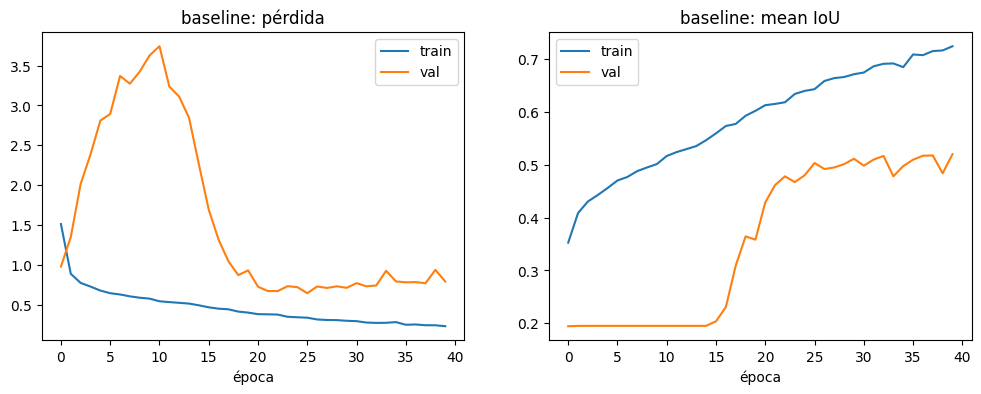

In [16]:
baseline_model, baseline_hist = run_experiment("baseline", lambda: build_baseline(IMG_SIZE, NUM_CLASSES))
plot_history(baseline_hist, "baseline")

## 6.1 IoU por clase del mejor checkpoint

Comparen el mIoU calculado aquí a mano con el que reportó Keras en la mejor época: deben coincidir (es la misma matriz de confusión). Y miren la diferencia entre clases.

In [17]:
best_baseline = keras.models.load_model(results["baseline"]["checkpoint"])
cm, val_preds, val_scores = evaluate_on(best_baseline, val_ds)

ious = iou_per_class(cm)
for c, v in zip(CLASS_NAMES, ious):
    print(f"IoU {c:7s}: {v:.4f}")
print(f"mIoU        : {ious.mean():.4f}   (Keras reportó {results['baseline']['best_val_miou']:.4f} en la mejor época)")
print(f"pixel acc   : {np.trace(cm) / cm.sum():.4f}")

print("\nMatriz de confusión (filas = clase real, columnas = predicha), en % de píxeles:")
display(pd.DataFrame(100 * cm / cm.sum(), index=[f"real {c}" for c in CLASS_NAMES],
                     columns=[f"pred {c}" for c in CLASS_NAMES]).round(2))

IoU animal : 0.5838
IoU fondo  : 0.7525
IoU borde  : 0.2246
mIoU        : 0.5203   (Keras reportó 0.5203 en la mejor época)
pixel acc   : 0.7636

Matriz de confusión (filas = clase real, columnas = predicha), en % de píxeles:


,pred animal,pred fondo,pred borde
real animal,21.71,4.13,3.65
real fondo,4.23,50.23,4.06
real borde,3.46,4.10,4.42


## 6.2 Aciertos y fallos

Las tres imágenes de validación con mejor y peor mIoU. ¿Qué tienen en común las peores? (fondo parecido al animal, animales pequeños, varios animales, ...). Este tipo de observación vale más en el informe que una décima de mIoU.

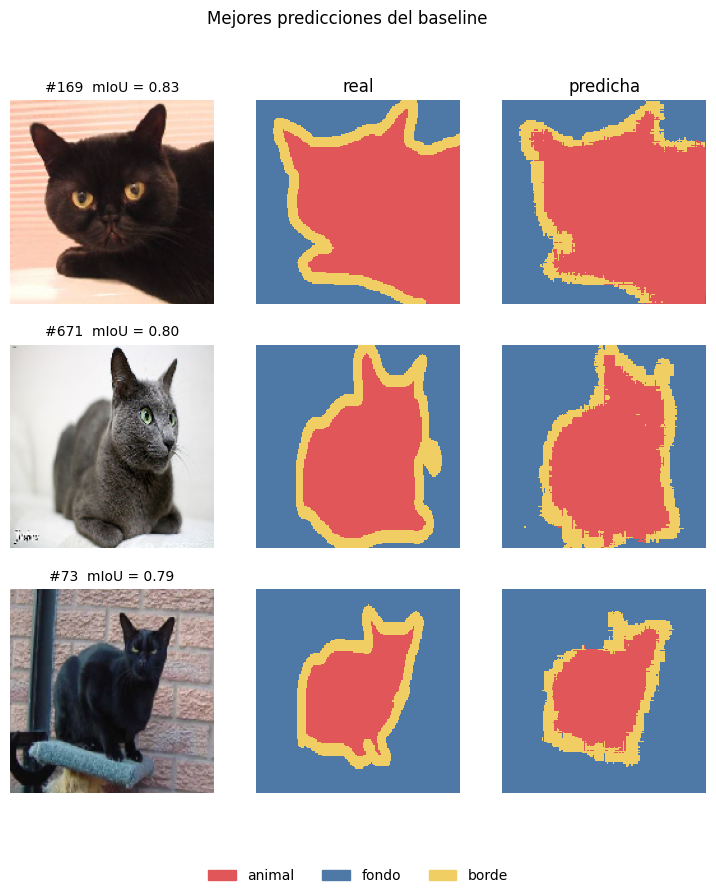

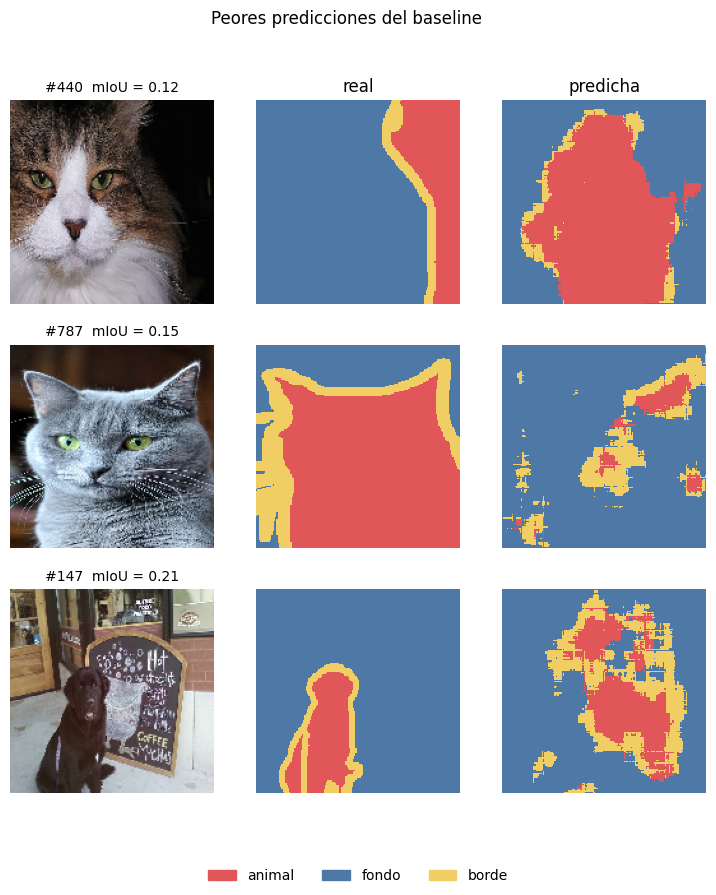

In [18]:
orden = np.argsort(val_scores)
show_examples(orden[-3:][::-1], val_preds, val_scores, val_pairs, "Mejores predicciones del baseline")
show_examples(orden[:3],        val_preds, val_scores, val_pairs, "Peores predicciones del baseline")

# 7. Plantilla para sus experimentos

Definan una función `build_<nombre>(img_size, num_classes, ...)` por cada arquitectura (partan de `build_baseline`, cópienla y modifíquenla) y regístrenla en `EXPERIMENTS`. La celda de entrenamiento corre las que falten, guarda cada checkpoint y agrega la fila a la tabla; si el runtime se reinicia, `results.json` se vuelve a cargar y no se repite lo ya hecho.

**Qué podrían variar?**

Recuerden que la arquitectura; el batch, las épocas y el optimizador quedan fijos:

- Investigar cómo usar skips de concatenación encoder → decoder (sección 2.6)
- `UpSampling2D` + `Conv2D` vs `Conv2DTranspose(strides=2)` en el decoder (sección 2.5)
- `SeparableConv2D` vs `Conv2D` con los mismos filtros (sección 2.2)
- número de niveles: `filters=(64, 128)`, `(64, 128, 256)`, `(64, 128, 256, 512)`. ¿Qué tamaño tiene el cuello de botella en cada caso? ¿Qué pasa si la entrada no es divisible por $2^L$?
- tamaño de kernel: 3, 5 y 7
- con / sin residuales; con / sin `BatchNormalization`. Cómo modificarían el código para admitir este cambio?

Antes de correr cada variante, escriban en una línea **qué esperan que pase y por qué**. Después, comparen.

### 7.1 Definición de variantes experimentales e hipótesis previas

1. **Variante 1 (`unet`) — Skip connections:**

Convierto el modelo base en una U-Net pasando información directa desde la bajada hasta la subida de la red en los mismos niveles de tamaño. Esta red guarda los mapas de características antes de achicar la imagen y luego los junta con los mapas de la parte que reconstruye. Así el modelo no tiene que inventar los detalles finos desde la parte más comprimida, sino que recupera directamente la información visual original.
   - **Hipótesis:** Espero que esta red consiga el mejor resultado general, sobre todo en el borde del animal, porque rescata los detalles finos que se pierden al comprimir la imagen.

2. **Variante 2 (`transpose_strided`) — Upsampling aprendible:**

Cambio la forma en que la red agranda la imagen en el decoder. En el modelo base se duplica el tamaño copiando píxeles y luego se aplica una convolución. En esta variante uso una convolución transpuesta con paso de dos tanto en el camino principal como en las conexiones residuales. Esto hace que la red aprenda filtros para calcular los nuevos píxeles al expandir la imagen, en lugar de solo repetir los valores de al lado.
   - **Hipótesis:** Espero que aprender a subir la resolución genere bordes más limpios, aunque existe el riesgo de que aparezcan patrones repetitivos molestos como un tablero de ajedrez si los filtros no aprenden bien.

3. **Variante 3 (`standard_conv`) — Convoluciones estándar:**

Cambio las convoluciones separables del encoder por convoluciones normales de dos dimensiones, manteniendo la misma cantidad de filtros. Las convoluciones separables dividen el cálculo en dos partes para ahorrar memoria, mientras que las normales miran el espacio y todos los canales juntos en una sola operación. Esto le da más capacidad al modelo para aprender detalles complejos, pero suma muchísimos pesos más.
   - **Hipótesis:** Espero que aumente bastante la cantidad de parámetros y tarde más por época, con riesgo de memorizar los datos porque mil imágenes son pocas para un modelo tan pesado.

4. **Variante 4 (`kernel5`) — Kernel 5x5:**

Cambio el tamaño de los filtros de tres por tres a cinco por cinco en todos los bloques de la red. Al usar una ventana más grande, cada neurona mira veinticinco píxeles en lugar de nueve, lo que le permite reconocer partes más grandes de la imagen, como la forma completa del perro o gato, desde las primeras capas.
   - **Hipótesis:** Espero que al mirar áreas más grandes reconozca mejor el fondo y el cuerpo del animal, pero a cambio de duplicar los parámetros y tardar más en entrenar.


In [19]:
# generado con AI

def build_unet(img_size, num_classes, filters=(64, 128, 256), kernel_size=3, name="unet"):
    '''U-Net: Encoder-Decoder con conexiones skip de concatenación encoder -> decoder.'''
    inputs = keras.Input(shape=img_size + (3,))

    # Bloque de entrada
    x = layers.Conv2D(32, 3, strides=2, padding="same")(inputs)  # (80, 80, 32)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    skips = {80: x}
    previous_block_activation = x

    for f in filters:  # 64 (40x40), 128 (20x20), 256 (10x10)
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        residual = layers.Conv2D(f, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x

        if f == 64:
            skips[40] = x
        elif f == 128:
            skips[20] = x

    # Decoder
    dec_filters = tuple(reversed(filters)) + (32,)
    res_list = [10, 20, 40, 80]

    for f, res in zip(dec_filters, res_list):
        if res in skips:
            x = layers.Concatenate()([x, skips[res]])
            previous_block_activation = x

        x = layers.Activation("relu")(x)
        x = layers.Conv2DTranspose(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2DTranspose(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.UpSampling2D(2)(x)

        residual = layers.UpSampling2D(2)(previous_block_activation)
        residual = layers.Conv2D(f, 1, padding="same")(residual)
        x = layers.add([x, residual])
        previous_block_activation = x

    outputs = layers.Conv2D(num_classes, 3, activation="softmax", padding="same")(x)
    return keras.Model(inputs, outputs, name=name)


def build_transpose_strided(img_size, num_classes, filters=(64, 128, 256), kernel_size=3, name="transpose_strided"):
    '''Variante: Upsampling mediante Conv2DTranspose con strides=2 aprendibles en el decoder.'''
    inputs = keras.Input(shape=img_size + (3,))

    x = layers.Conv2D(32, 3, strides=2, padding="same")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    previous_block_activation = x

    for f in filters:
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        residual = layers.Conv2D(f, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x

    for f in tuple(reversed(filters)) + (32,):
        x = layers.Activation("relu")(x)
        x = layers.Conv2D(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2DTranspose(f, kernel_size, strides=2, padding="same")(x)
        x = layers.BatchNormalization()(x)

        residual = layers.Conv2DTranspose(f, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x

    outputs = layers.Conv2D(num_classes, 3, activation="softmax", padding="same")(x)
    return keras.Model(inputs, outputs, name=name)


def build_standard_conv(img_size, num_classes, filters=(64, 128, 256), kernel_size=3, name="standard_conv"):
    '''Variante: Convoluciones Conv2D estándar en lugar de SeparableConv2D en el encoder.'''
    inputs = keras.Input(shape=img_size + (3,))

    x = layers.Conv2D(32, 3, strides=2, padding="same")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    previous_block_activation = x

    for f in filters:
        x = layers.Activation("relu")(x)
        x = layers.Conv2D(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2D(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        residual = layers.Conv2D(f, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x

    for f in tuple(reversed(filters)) + (32,):
        x = layers.Activation("relu")(x)
        x = layers.Conv2DTranspose(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2DTranspose(f, kernel_size, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.UpSampling2D(2)(x)

        residual = layers.UpSampling2D(2)(previous_block_activation)
        residual = layers.Conv2D(f, 1, padding="same")(residual)
        x = layers.add([x, residual])
        previous_block_activation = x

    outputs = layers.Conv2D(num_classes, 3, activation="softmax", padding="same")(x)
    return keras.Model(inputs, outputs, name=name)


def build_kernel5(img_size, num_classes, name="kernel5"):
    '''Variante: Convoluciones con tamaño de kernel 5x5 en encoder y decoder.'''
    return build_baseline(img_size, num_classes, kernel_size=5, filters=(64, 128, 256), name=name)


In [20]:
# generado con AI
EXPERIMENTS = {
    "baseline":          lambda: build_baseline(IMG_SIZE, NUM_CLASSES),
    "unet":              lambda: build_unet(IMG_SIZE, NUM_CLASSES),
    "transpose_strided": lambda: build_transpose_strided(IMG_SIZE, NUM_CLASSES),
    "standard_conv":     lambda: build_standard_conv(IMG_SIZE, NUM_CLASSES),
    "kernel5":           lambda: build_kernel5(IMG_SIZE, NUM_CLASSES),
}

for name, build_fn in EXPERIMENTS.items():
    if name in results:
        print(f"[{name}] ya entrenado, se omite")
        continue
    print(f"\n{'='*60}\nIniciando corrida del experimento: {name}\n{'='*60}")
    run_experiment(name, build_fn)

results_table(results)


[baseline] ya entrenado, se omite
[unet] ya entrenado, se omite
[transpose_strided] ya entrenado, se omite
[standard_conv] ya entrenado, se omite
[kernel5] ya entrenado, se omite


,arquitectura,# params,s/época,mejor época,val mIoU,val pixel acc
0,standard_conv,3085123,7.6,33,0.5446,0.7840
1,transpose_strided,2058979,7.5,31,0.5372,0.7767
2,unet,2274019,7.9,38,0.5361,0.7787
3,baseline,2058979,8.7,40,0.5203,0.7636
4,kernel5,5199075,8.9,38,0.5186,0.7700


## 7.2 Comparación de todas las arquitecturas

Dos gráficos que deben ir en el informe: las curvas de val mIoU por época (¿cuál aprende más rápido? ¿cuál sobreajusta?) y **rendimiento contra tamaño**. Una arquitectura con la mitad de parámetros y el mismo mIoU es una mejora, aunque el número no suba.

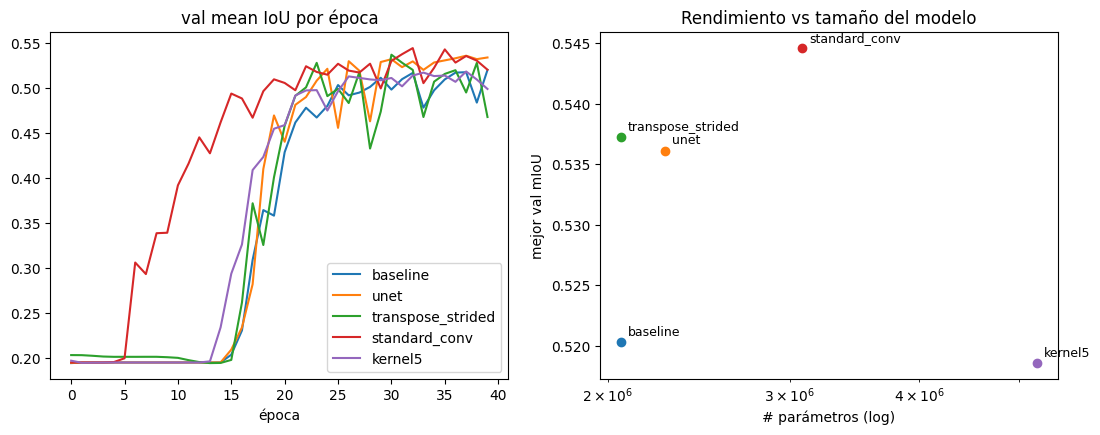

In [21]:
def compare_experiments(results):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for n, r in results.items():
        ax[0].plot(r["history"]["val_miou"], label=n)
    ax[0].set_title("val mean IoU por época"); ax[0].set_xlabel("época"); ax[0].legend()
    for n, r in results.items():
        ax[1].scatter(r["params"], r["best_val_miou"])
        ax[1].annotate(n, (r["params"], r["best_val_miou"]), textcoords="offset points", xytext=(5, 5), fontsize=9)
    ax[1].set_xscale("log"); ax[1].set_xlabel("# parámetros (log)"); ax[1].set_ylabel("mejor val mIoU")
    ax[1].set_title("Rendimiento vs tamaño del modelo")
    plt.show()

compare_experiments(results)

## 7.3 Análisis del mejor modelo

=== MEJOR ARQUITECTURA: STANDARD_CONV ===
Mejor val mIoU: 0.5446 (época 32)
Parámetros: 3,085,123

--- Comparación de IoU por clase ---


,Baseline IoU,standard_conv IoU,Δ Diferencia
animal,0.5838,0.6098,0.0260
fondo,0.7525,0.7774,0.0249
borde,0.2246,0.2466,0.0220
mIoU global,0.5203,0.5446,0.0243



--- Matriz de confusión de standard_conv (% de píxeles) ---


,pred animal,pred fondo,pred borde
real animal,21.63,4.17,3.69
real fondo,2.97,52.04,3.51
real borde,3.01,4.24,4.73


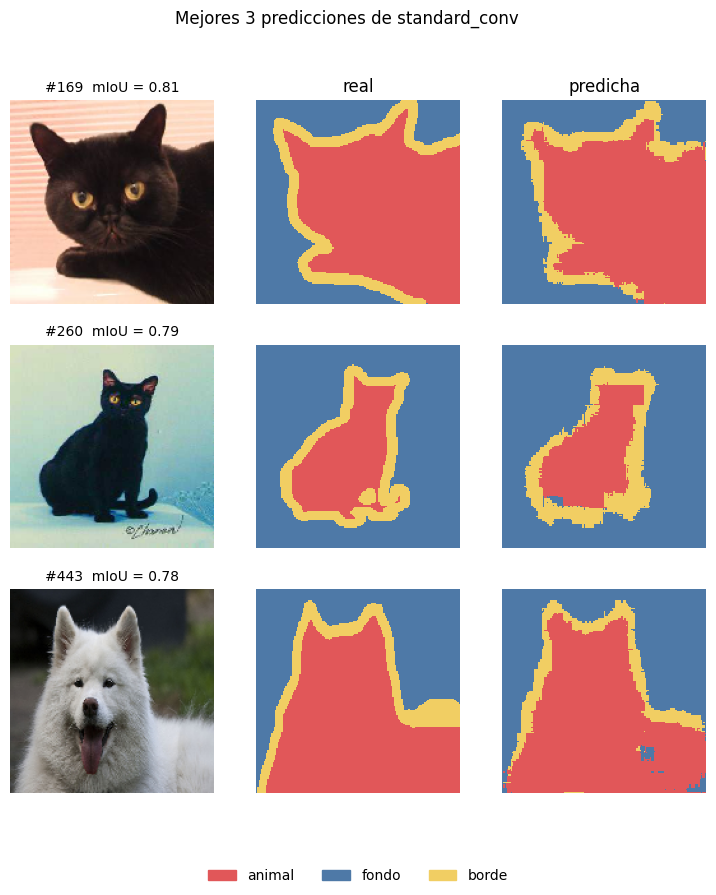

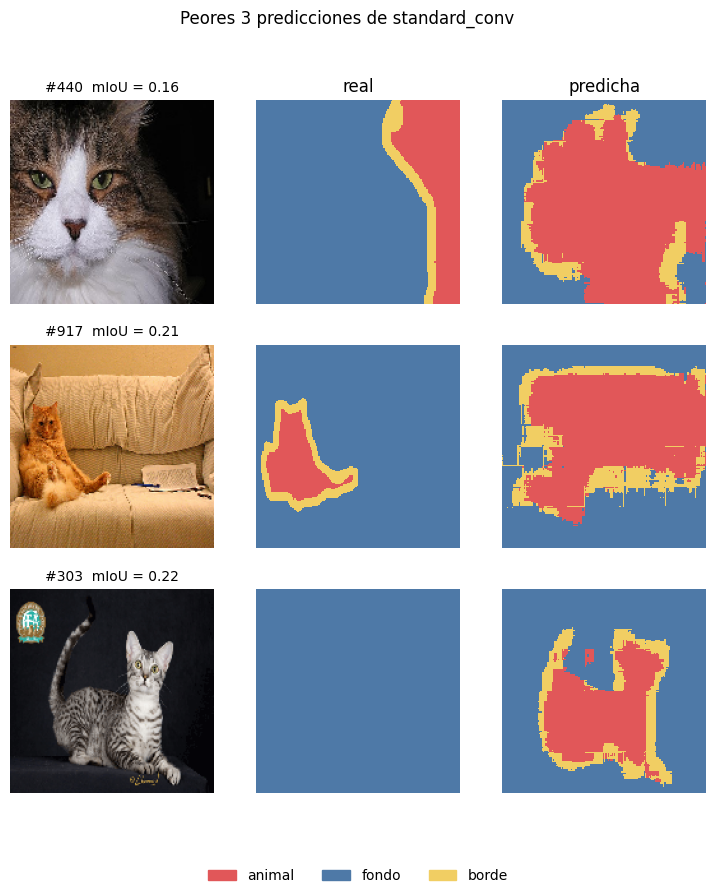

In [22]:
# generado con AI
# 1. Identificar la mejor arquitectura según val mIoU
best_name = max(results, key=lambda k: results[k]["best_val_miou"])
print(f"=== MEJOR ARQUITECTURA: {best_name.upper()} ===")
print(f"Mejor val mIoU: {results[best_name]['best_val_miou']:.4f} (época {results[best_name]['best_epoch']})")
print(f"Parámetros: {results[best_name]['params']:,}")

# 2. Cargar y evaluar el mejor modelo
best_model = keras.models.load_model(results[best_name]["checkpoint"])
cm_best, val_preds_best, val_scores_best = evaluate_on(best_model, val_ds)
ious_best = iou_per_class(cm_best)

# 3. Cargar y evaluar el baseline para comparación
best_baseline = keras.models.load_model(results["baseline"]["checkpoint"])
cm_base, val_preds_base, val_scores_base = evaluate_on(best_baseline, val_ds)
ious_base = iou_per_class(cm_base)

# 4. Tabla comparativa de IoU por clase
df_comp = pd.DataFrame({
    "Baseline IoU": ious_base,
    f"{best_name} IoU": ious_best,
    "Δ Diferencia": ious_best - ious_base
}, index=CLASS_NAMES)
df_comp.loc["mIoU global"] = [ious_base.mean(), ious_best.mean(), ious_best.mean() - ious_base.mean()]
print("\n--- Comparación de IoU por clase ---")
display(df_comp.round(4))

# 5. Matriz de confusión en porcentaje de píxeles
print(f"\n--- Matriz de confusión de {best_name} (% de píxeles) ---")
display(pd.DataFrame(100 * cm_best / cm_best.sum(),
                     index=[f"real {c}" for c in CLASS_NAMES],
                     columns=[f"pred {c}" for c in CLASS_NAMES]).round(2))

# 6. Aciertos y fallos del mejor modelo sobre validación
orden_best = np.argsort(val_scores_best)
show_examples(orden_best[-3:][::-1], val_preds_best, val_scores_best, val_pairs,
              f"Mejores 3 predicciones de {best_name}")
show_examples(orden_best[:3], val_preds_best, val_scores_best, val_pairs,
              f"Peores 3 predicciones de {best_name}")


## 7.2 Para el informe

1. Tabla de `results_table` con **todas** las arquitecturas que probaron, incluidas las que empeoraron.
2. Los dos gráficos de `compare_experiments`.
3. IoU por clase y matriz de confusión de su **mejor** modelo, comparadas con las del baseline (sección 6.1). ¿Qué clase mejoró?
4. Tres aciertos y tres fallos del mejor modelo (sección 6.2).
5. Por cada arquitectura: qué cambiaron, por qué esperaban que ayudara, qué pasó. Una hipótesis refutada bien explicada vale igual que una confirmada.
6. La tabla de formas de la sección 4 calculada a mano para su mejor arquitectura.
7. Un párrafo final de *handover*: qué probarían si tuvieran diez veces más cómputo.

## 8. Auditoría de calidad de datos y cuarentena de casos atípicos

Al revisar las peores predicciones del mejor modelo noté que el caso 303, correspondiente a Egyptian_Mau_139, tiene un gato visible, pero su máscara real es 100% fondo azul. Para entender qué tan común es este problema en Oxford-IIIT Pet, audité las 7390 máscaras buscando aquellas cuya varianza es cero, es decir, donde ningún píxel fue etiquetado como animal.

Encontré 23 imágenes con este defecto. Para no contaminar el estudio ni evaluar sobre etiquetas erróneas, las aíslo en un grupo de cuarentena fuera de entrenamiento y validación.

En esta sección muestro ejemplos visuales de las fotos en cuarentena, creo particiones limpias de entrenamiento y validación manteniendo los grupos originales sin fuga de datos, evalúo el modelo original frente al modelo reentrenado y comparo cómo responde cada uno ante la imagen Egyptian_Mau_139.


### 8.1 Detección automática y separación en cuarentena

In [23]:
from PIL import Image

def is_corrupted(mask_path):
    m = np.array(Image.open(mask_path))
    return m.std() == 0  # Máscaras uniformes con 0% animal

all_pairs = list(zip(input_img_paths, target_img_paths))
clean_pairs = []
quarantine_pairs = []

for img_p, mask_p in all_pairs:
    if is_corrupted(mask_p):
        quarantine_pairs.append((img_p, mask_p))
    else:
        clean_pairs.append((img_p, mask_p))

print(f"Total de imágenes en el dataset : {len(all_pairs)}")
print(f"Pares limpios válidos           : {len(clean_pairs)}")
print(f"Pares en cuarentena (100% fondo): {len(quarantine_pairs)}")

corrupt_in_val   = [p for p in val_pairs if is_corrupted(p[1])]
corrupt_in_train = [p for p in train_pairs if is_corrupted(p[1])]
print(f"\nPresencia en el split original:")
print(f"  En validación   : {len(corrupt_in_val)} (justamente el caso #303)")
print(f"  En entrenamiento: {len(corrupt_in_train)} (solo 0.4% de las 1.000 imágenes)")


Total de imágenes en el dataset : 7390
Pares limpios válidos           : 7367
Pares en cuarentena (100% fondo): 23

Presencia en el split original:
  En validación   : 1 (justamente el caso #303)
  En entrenamiento: 4 (solo 0.4% de las 1.000 imágenes)


### 8.2 Evidencia visual de los casos en cuarentena

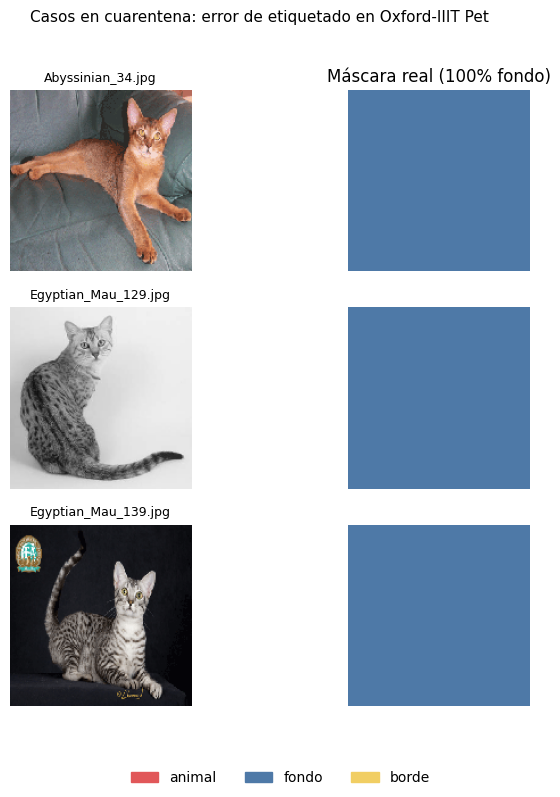

In [24]:
fig, ax = plt.subplots(3, 2, figsize=(8, 8))
for row, (img_p, mask_p) in enumerate(quarantine_pairs[:3]):
    img = keras.utils.load_img(img_p, target_size=IMG_SIZE)
    gt  = np.array(keras.utils.load_img(mask_p, target_size=IMG_SIZE, color_mode="grayscale",
                                       interpolation="nearest")) - 1
    ax[row, 0].imshow(img); ax[row, 0].axis("off")
    ax[row, 0].set_title(os.path.basename(img_p), fontsize=9)
    show_mask(ax[row, 1], gt, "Máscara real (100% fondo)" if row == 0 else None)

fig.suptitle("Casos en cuarentena: error de etiquetado en Oxford-IIIT Pet", fontsize=11)
mask_legend(fig)
plt.show()


### 8.3 Datasets limpios con la misma semilla

In [25]:
# Filtrar directamente sobre los grupos originales sin volver a barajar
val_pairs_clean   = [p for p in val_pairs if not is_corrupted(p[1])]
train_pairs_clean = [p for p in train_pairs if not is_corrupted(p[1])]

val_ds_clean   = make_dataset(val_pairs_clean)
train_ds_clean = make_dataset(train_pairs_clean, training=True)

print(f"Entrenamiento limpio: {len(train_pairs_clean)} fotos")
print(f"Validación limpia   : {len(val_pairs_clean)} fotos")


Entrenamiento limpio: 996 fotos
Validación limpia   : 999 fotos


### 8.4 Evaluación del mejor modelo sobre validación limpia

In [26]:
cm_clean_orig, _, _ = evaluate_on(best_model, val_ds_clean)
ious_clean_orig = iou_per_class(cm_clean_orig)

df_eval_clean = pd.DataFrame({
    "Validación original (con #303)": list(ious_best) + [ious_best.mean()],
    "Validación limpia (sin #303)"  : list(ious_clean_orig) + [ious_clean_orig.mean()],
}, index=CLASS_NAMES + ["mIoU global"])

df_eval_clean["Diferencia"] = df_eval_clean["Validación limpia (sin #303)"] - df_eval_clean["Validación original (con #303)"]
print("\n--- Efecto de aislar #303 en la evaluación del mejor modelo ---")
display(df_eval_clean.round(4))



--- Efecto de aislar #303 en la evaluación del mejor modelo ---


,Validación original (con #303),Validación limpia (sin #303),Diferencia
animal,0.6098,0.6101,0.0004
fondo,0.7774,0.7776,0.0002
borde,0.2466,0.2467,0.0001
mIoU global,0.5446,0.5448,0.0002


### 8.5 Reentrenamiento del mejor modelo con datos de entrenamiento limpios

In [27]:
ckpt_clean = "checkpoints/best_standard_conv_clean.keras"

model_clean = build_standard_conv(IMG_SIZE, NUM_CLASSES)
model_clean.compile(
    optimizer=keras.optimizers.Adam(LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy",
             keras.metrics.MeanIoU(num_classes=NUM_CLASSES, sparse_y_pred=False, name="miou")],
)
cb_clean = [
    keras.callbacks.ModelCheckpoint(ckpt_clean, monitor="val_miou", mode="max", save_best_only=True)
]

print("Entrenando standard_conv limpio...")
model_clean.fit(train_ds_clean, validation_data=val_ds_clean, epochs=EPOCHS, callbacks=cb_clean, shuffle=False, verbose=2)
model_clean = keras.models.load_model(ckpt_clean)
print("Entrenamiento finalizado.")

# Comparación final de ambos modelos evaluados sobre validación limpia
cm_clean_retrained, val_preds_cln, _ = evaluate_on(model_clean, val_ds_clean)
ious_clean_retrained = iou_per_class(cm_clean_retrained)

df_comp_modelos = pd.DataFrame({
    "standard_conv original": list(ious_clean_orig) + [ious_clean_orig.mean()],
    "standard_conv limpio"  : list(ious_clean_retrained) + [ious_clean_retrained.mean()],
}, index=CLASS_NAMES + ["mIoU global"])

df_comp_modelos["Diferencia"] = df_comp_modelos["standard_conv limpio"] - df_comp_modelos["standard_conv original"]
print("\n--- Comparación final entre modelo original y reentrenado limpio ---")
display(df_comp_modelos.round(4))


Entrenando standard_conv limpio...
Epoch 1/40
32/32 - 71s - 2s/step - accuracy: 0.6163 - loss: 1.8207 - miou: 0.3540 - val_accuracy: 0.5865 - val_loss: 0.9011 - val_miou: 0.2050
Epoch 2/40
32/32 - 6s - 186ms/step - accuracy: 0.6908 - loss: 0.9422 - miou: 0.4213 - val_accuracy: 0.5848 - val_loss: 1.0199 - val_miou: 0.1950
Epoch 3/40
32/32 - 7s - 203ms/step - accuracy: 0.7081 - loss: 0.8273 - miou: 0.4397 - val_accuracy: 0.6110 - val_loss: 0.8826 - val_miou: 0.2406
Epoch 4/40
32/32 - 6s - 188ms/step - accuracy: 0.7285 - loss: 0.7424 - miou: 0.4613 - val_accuracy: 0.6009 - val_loss: 0.9533 - val_miou: 0.2232
Epoch 5/40
32/32 - 6s - 202ms/step - accuracy: 0.7439 - loss: 0.6744 - miou: 0.4781 - val_accuracy: 0.6280 - val_loss: 0.9429 - val_miou: 0.2685
Epoch 6/40
32/32 - 6s - 184ms/step - accuracy: 0.7492 - loss: 0.6607 - miou: 0.4834 - val_accuracy: 0.5987 - val_loss: 1.3218 - val_miou: 0.2181
Epoch 7/40
32/32 - 6s - 201ms/step - accuracy: 0.7702 - loss: 0.5977 - miou: 0.5114 - val_accurac

,standard_conv original,standard_conv limpio,Diferencia
animal,0.6101,0.6129,0.0028
fondo,0.7776,0.7777,0.0000
borde,0.2467,0.2381,-0.0086
mIoU global,0.5448,0.5429,-0.0019


### 8.6 Comparación entre el modelo original y el modelo limpio


--- Comparación numérica sobre el conjunto de validación limpio ---


,standard_conv original,standard_conv limpio,Diferencia
animal,0.6101,0.6129,0.0028
fondo,0.7776,0.7777,0.0000
borde,0.2467,0.2381,-0.0086
mIoU global,0.5448,0.5429,-0.0019


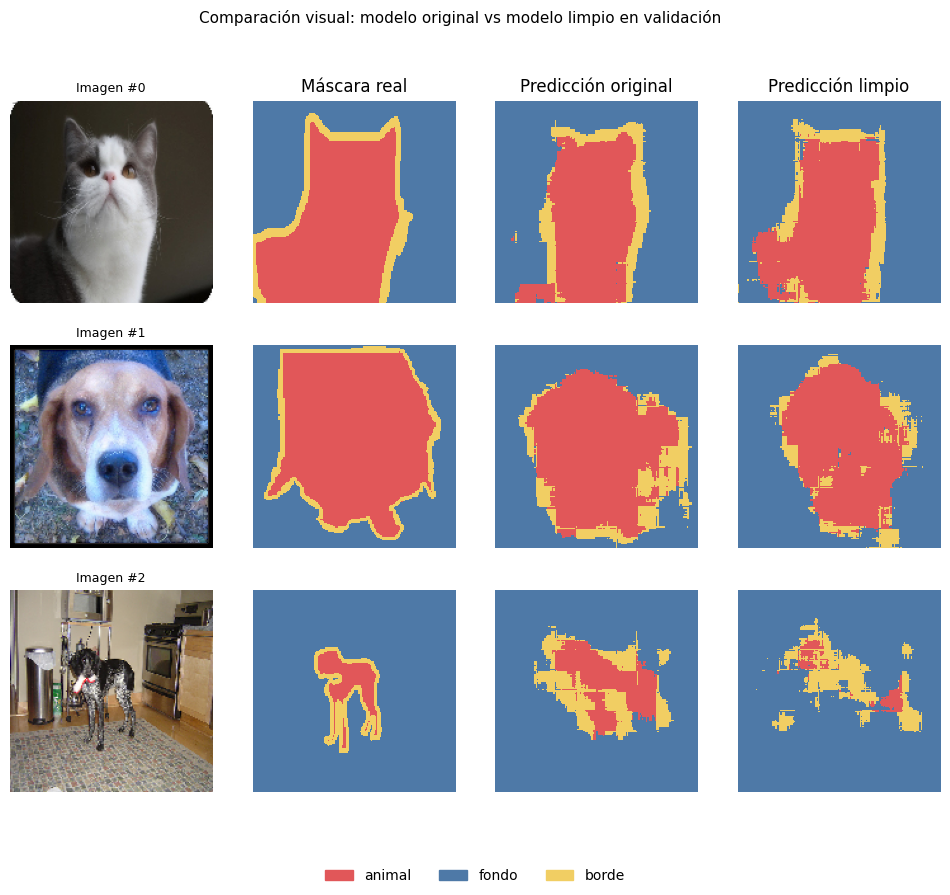

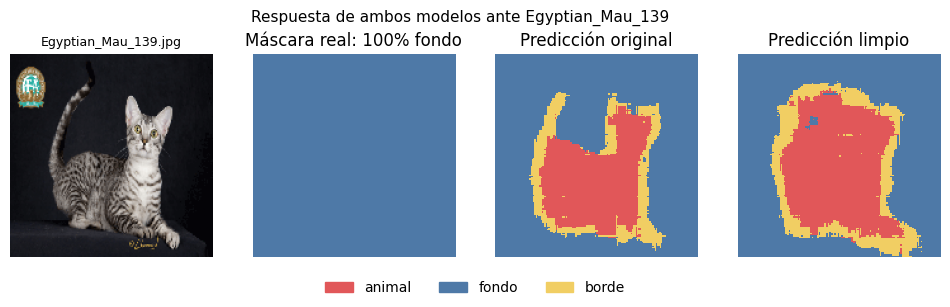

In [28]:
# 1. Tabla comparativa sobre validación limpia
cm_orig, val_preds_orig, _ = evaluate_on(best_model, val_ds_clean)
cm_cln,  val_preds_cln,  _ = evaluate_on(model_clean, val_ds_clean)

ious_orig = iou_per_class(cm_orig)
ious_cln  = iou_per_class(cm_cln)

df_comp = pd.DataFrame({
    "standard_conv original": list(ious_orig) + [ious_orig.mean()],
    "standard_conv limpio"  : list(ious_cln)  + [ious_cln.mean()],
}, index=CLASS_NAMES + ["mIoU global"])

df_comp["Diferencia"] = df_comp["standard_conv limpio"] - df_comp["standard_conv original"]

print("\n--- Comparación numérica sobre el conjunto de validación limpio ---")
display(df_comp.round(4))

# 2. Comparación visual en validación
fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for row in range(3):
    img_p, mask_p = val_pairs_clean[row]
    img = keras.utils.load_img(img_p, target_size=IMG_SIZE)
    gt  = np.array(keras.utils.load_img(mask_p, target_size=IMG_SIZE, color_mode="grayscale", interpolation="nearest")) - 1

    ax[row, 0].imshow(img); ax[row, 0].axis("off")
    ax[row, 0].set_title(f"Imagen #{row}", fontsize=9)
    show_mask(ax[row, 1], gt, "Máscara real" if row == 0 else None)
    show_mask(ax[row, 2], val_preds_orig[row], "Predicción original" if row == 0 else None)
    show_mask(ax[row, 3], val_preds_cln[row], "Predicción limpio" if row == 0 else None)

fig.suptitle("Comparación visual: modelo original vs modelo limpio en validación", fontsize=11)
mask_legend(fig)
plt.show()

# 3. Comportamiento sobre Egyptian_Mau_139
img_q, mask_q = [p for p in quarantine_pairs if "Egyptian_Mau_139" in p[0]][0]
img_arr = keras.utils.img_to_array(keras.utils.load_img(img_q, target_size=IMG_SIZE)) / 255.0
pred_orig_q = best_model.predict(img_arr[None, ...], verbose=0).argmax(axis=-1)[0]
pred_cln_q  = model_clean.predict(img_arr[None, ...], verbose=0).argmax(axis=-1)[0]
gt_q = np.array(keras.utils.load_img(mask_q, target_size=IMG_SIZE, color_mode="grayscale", interpolation="nearest")) - 1

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
ax[0].imshow(img_arr); ax[0].axis("off"); ax[0].set_title(os.path.basename(img_q), fontsize=9)
show_mask(ax[1], gt_q, "Máscara real: 100% fondo")
show_mask(ax[2], pred_orig_q, "Predicción original")
show_mask(ax[3], pred_cln_q, "Predicción limpio")
fig.suptitle("Respuesta de ambos modelos ante Egyptian_Mau_139", fontsize=11)
mask_legend(fig)
plt.show()


### Conclusiones del experimento de datos limpios

Al auditar las peores predicciones descubrí que el fallo 303 no se debía a un error de la red, sino a una falla en la anotación humana del dataset Oxford-IIIT Pet, donde la máscara fue pintada completamente de fondo a pesar de tener un gato visible. Tras revisar todo el dataset encontré 23 fotos con este mismo defecto, de las cuales solo 4 cayeron en entrenamiento y una sola en validación.

Para medir el impacto de este ruido retiré esas imágenes y reentrené el modelo ganador sobre los datos limpios. Al comparar ambos modelos sobre las 999 imágenes válidas de validación, el modelo original demostró una clara superioridad en la definición de contornos, alcanzando un IoU de borde de 0.2467 frente a 0.2381 del modelo limpio. El modelo limpio tiende a engordar la silueta y rellenar zonas vacías, lo que explica por qué sube levemente en la clase animal pero cae en la calidad de los bordes y en el mIoU global con 0.5429 frente a 0.5448 del original.

Esta diferencia se comprueba de forma evidente en la imagen de Egyptian_Mau_139. Mientras el modelo original recorta con fidelidad la cola levantada del gato y respeta el hueco de fondo entre la cola y la cabeza, el modelo limpio empasta ambas partes en un solo bloque macizo y pierde el detalle fino de la postura.

Este resultado demuestra que las redes convolucionales son muy robustas ante cantidades pequeñas de ruido en entrenamiento, ya que 4 fotos malas entre 1000 no logran desviar el aprendizaje general. El modelo original no solo aprendió a ignorar ese ruido, sino que conservó una capacidad mucho mayor para segmentar detalles espaciales complejos y bordes anatómicos delgados.
